In [ ]:
import pandas as pd
import sys

sys.path.append("..")

from src.data.load import (
    load_ratings,
    load_genres,
    load_movies,
    load_users,
)

from src.utils.config import RATING_SCALE

ratings = load_ratings()


def count_ratings(value: int) -> None:
    print(f" Number of rate '{value}': {(ratings['rating']==value).sum()}")


for value in range(RATING_SCALE[0], RATING_SCALE[1] + 1):
    count_ratings(value)

 Number of rate '1': 6110
 Number of rate '2': 11370
 Number of rate '3': 27145
 Number of rate '4': 34174
 Number of rate '5': 21201


In [ ]:
voting_users = ratings.groupby("user_id")["rating"].count()
voting_users_df = voting_users.reset_index()
voting_users_df.columns = ["user_id", "count_rates"]
voting_users_df

,user_id,count_rates
0,1,272
1,2,62
2,3,54
3,4,24
4,5,175
...,...,...
938,939,49
939,940,107
940,941,22
941,942,79


In [18]:
voting_users.describe()

count    943.000000
mean     106.044539
std      100.931743
min       20.000000
25%       33.000000
50%       65.000000
75%      148.000000
max      737.000000
Name: rating, dtype: float64

Text(0.5, 1.0, "Users' activity distribution")

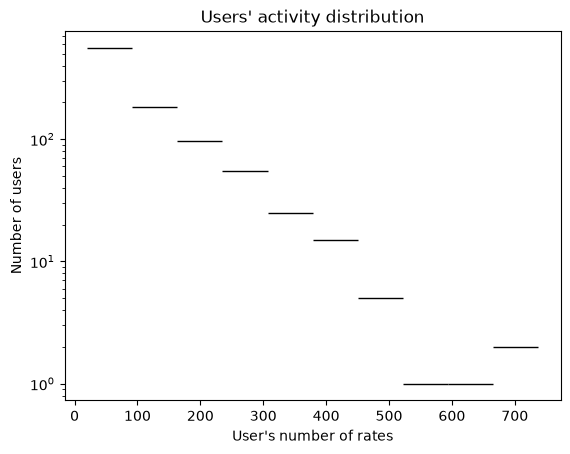

In [ ]:
import seaborn as sns

hist_users = sns.histplot(voting_users, bins=10, log_scale=(False, True))
hist_users.set_xlabel("User's number of rates")
hist_users.set_ylabel("Number of users")
hist_users.set_title("Users' activity distribution")

In [ ]:
movies_count_rated = ratings.groupby("movie_id")["rating"].count()
movies_count_rated.describe()

count    1682.000000
mean       59.453032
std        80.383846
min         1.000000
25%         6.000000
50%        27.000000
75%        80.000000
max       583.000000
Name: rating, dtype: float64

Text(0.5, 1.0, 'Distribution of How many times were films rated')

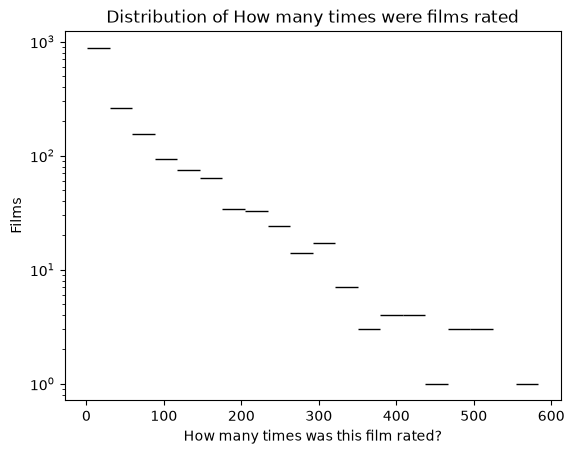

In [ ]:
counted_movies = sns.histplot(movies_count_rated, bins=20, log_scale=(False, True))
counted_movies.set_xlabel("How many times was this film rated?")
counted_movies.set_ylabel("Films")
counted_movies.set_title("Distribution of How many times were films rated")

In [35]:
movies_count_rated.sort_values(ascending=False)

movie_id
50      583
258     509
100     508
181     507
294     485
       ... 
1626      1
1630      1
1632      1
1681      1
1682      1
Name: rating, Length: 1682, dtype: int64

In [ ]:
movies = load_movies()
movies_count_rated_df = movies_count_rated.reset_index()
movies_count_rated_df.columns = ["movie_id", "count_rates"]
top_rated_films = pd.merge(movies, movies_count_rated_df, how="left")
top_rated_films = top_rated_films.sort_values("count_rates", ascending=False)
top_rated_films.head(20)

,movie_id,title,release_date,count_rates
49,50,Star Wars (1977),01-Jan-1977,583
257,258,Contact (1997),11-Jul-1997,509
99,100,Fargo (1996),14-Feb-1997,508
180,181,Return of the Jedi (1983),14-Mar-1997,507
293,294,Liar Liar (1997),21-Mar-1997,485
285,286,"English Patient, The (1996)",15-Nov-1996,481
287,288,Scream (1996),20-Dec-1996,478
0,1,Toy Story (1995),01-Jan-1995,452
299,300,Air Force One (1997),01-Jan-1997,431
120,121,Independence Day (ID4) (1996),03-Jul-1996,429


Text(0.5, 1.0, 'Top 20 most rated movies')

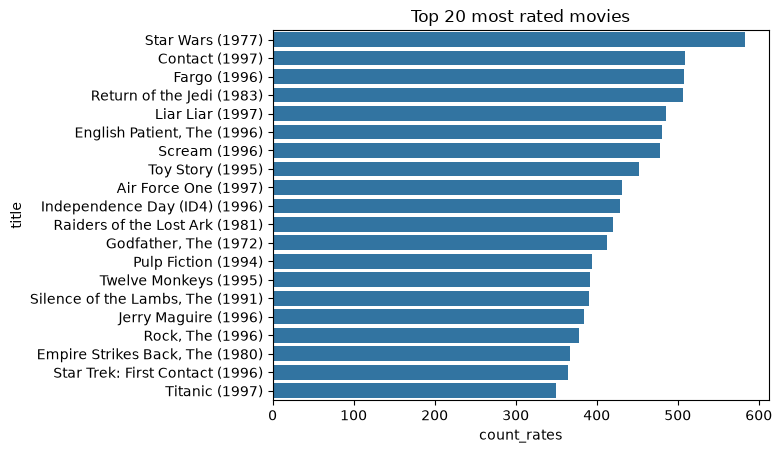

In [ ]:
top_films_bar_chart = sns.barplot(data=top_rated_films[:20], x="count_rates", y="title")
top_films_bar_chart.set_title("Top 20 most rated movies")

In [ ]:
avg_ratings = ratings.groupby("movie_id")["rating"].agg(["count", "mean"])
mask = avg_ratings["count"] >= 50
avg_ratings = avg_ratings[mask]
avg_ratings = avg_ratings.sort_values("mean", ascending=False)
avg_ratings

,count,mean
movie_id,,
408,112,4.491071
318,298,4.466443
169,118,4.466102
483,243,4.456790
114,67,4.447761
...,...,...
122,106,2.339623
988,86,2.313953
120,67,2.238806


In [ ]:
avg_ratings_df = avg_ratings.reset_index()
avg_ratings_df.columns = ["movie_id", "count_rates", "avg_rate"]
top_avg_rated_movies = pd.merge(movies, avg_ratings_df, how="left")
top_avg_rated_movies = top_avg_rated_movies.dropna()
top_avg_rated_movies = top_avg_rated_movies.sort_values("avg_rate", ascending=False)
top_avg_rated_movies

,movie_id,title,release_date,count_rates,avg_rate
407,408,"Close Shave, A (1995)",28-Apr-1996,112.0,4.491071
317,318,Schindler's List (1993),01-Jan-1993,298.0,4.466443
168,169,"Wrong Trousers, The (1993)",01-Jan-1993,118.0,4.466102
482,483,Casablanca (1942),01-Jan-1942,243.0,4.456790
113,114,Wallace & Gromit: The Best of Aardman Animatio...,05-Apr-1996,67.0,4.447761
...,...,...,...,...,...
121,122,"Cable Guy, The (1996)",14-Jun-1996,106.0,2.339623
987,988,"Beautician and the Beast, The (1997)",07-Feb-1997,86.0,2.313953
119,120,Striptease (1996),28-Jun-1996,67.0,2.238806
686,687,McHale's Navy (1997),18-Apr-1997,69.0,2.188406


Text(0.5, 1.0, 'Top 20 best rated films')

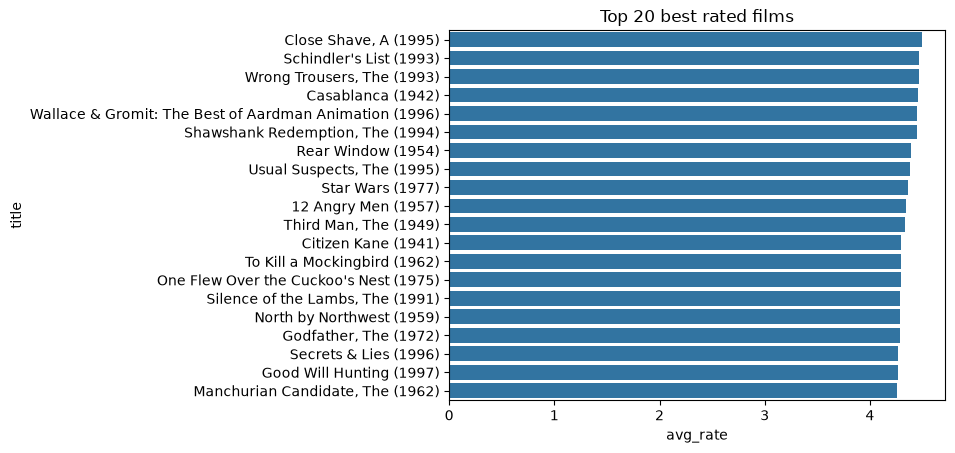

In [ ]:
top_20_best_rated_chart = sns.barplot(
    data=top_avg_rated_movies[:20], x="avg_rate", y="title"
)
top_20_best_rated_chart.set_title("Top 20 best rated films")

In [ ]:
def show_info() -> None:
    no_of_users = ratings["user_id"].nunique()
    no_of_films = ratings["movie_id"].nunique()
    pairs = no_of_films * no_of_users
    filled = round(100 * len(ratings) / pairs, 2)
    print(f"Number of users: {no_of_users}")
    print(f"Number of films: {no_of_films}")
    print(f"Number of possible pairs: {pairs}")
    print(f"Filled: {len(ratings)}")
    print(f"Percentage of filled: {filled}%")
    print(f"Percentage of unfilled: {100-filled}%")


show_info()

Number of users: 943
Number of films: 1682
Number of possible pairs: 1586126
Filled: 100000
Percentage of filled: 6.3%
Percentage of unfilled: 93.7%
